# Assignment: Build and Test a Machine-Learned Interatomic Potential



### Instructions
1. Complete every cell marked `# TODO`. Do **not** change the names or signatures of the functions you are asked to write, because the check cells call them.
2. After each task, run the **check cell** that follows it. A check prints `PASSED` when your implementation is correct. Passing checks is necessary but not sufficient for full marks: plots, tables and written answers are graded too.
3. Only NumPy and Matplotlib are allowed. Do not import ASE, PyTorch, scikit-learn or any MLIP package.
4. Use the practice-session notebook and the class notes as references. Copying code from the practice notebook is allowed **only** where it is marked as provided here. Everything else must be written by you.
5. Submit the executed notebook (`.ipynb`) with all outputs visible.

### The problem
You will build a linear MLIP for an 8-atom cluster described by a reference potential that differs from the one in the practice session: a **Morse** pair potential plus a three-body term that favours **90°** bond angles. All quantities are in reduced units ($D_e=1$, $r_0=1$, $m=1$, $k_B=1$).


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def check(cond, msg=""):
    print("PASSED" if cond else f"FAILED  {msg}")

# ---- provided helpers (same as in the practice session) ----
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]          # D[i, j] = r_j - r_i
    return D, np.linalg.norm(D, axis=-1)

def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

rng = np.random.default_rng(2026)

---
## Task A. Morse potential: energy and analytic forces
$$
V(r)=D_e\Big[\big(1-e^{-a(r-r_0)}\big)^2-1\Big],\qquad E_{\rm Morse}=\sum_{i<j}V(r_{ij})
$$

with $D_e=1$, $a=3$, $r_0=1$.

**A1 (3 pts).** Show by hand (write it in the markdown cell below) that $V(r_0)=-D_e$ and that

$$
V'(r)=2aD_e\,e^{-a(r-r_0)}\big(1-e^{-a(r-r_0)}\big).
$$

**A2 (7 pts).** Implement `morse_energy(R)` and `morse_forces(R)`. The force must be **analytic** (use $\mathbf F_i=\sum_{j\ne i}V'(r_{ij})\,\mathbf d_{ij}/r_{ij}$ with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$). Do not call `numerical_forces` inside `morse_forces`.

### A1. Your derivation:

**1. Verification of $V(r_0) = -D_e$:**
Given the Morse potential:
$$V(r) = D_e \Big[ \big(1 - e^{-a(r-r_0)}\big)^2 - 1 \Big]$$
Substitute $r = r_0$:
$$V(r_0) = D_e \Big[ \big(1 - e^{-a(0)}\big)^2 - 1 \Big] = D_e \Big[ (1 - 1)^2 - 1 \Big] = D_e [ -1 ] = -D_e.$$

**2. Derivation of $V'(r)$:**
Let $u(r) = 1 - e^{-a(r-r_0)}$.
Then $V(r) = D_e [u(r)^2 - 1]$.
Taking the derivative with respect to $r$ using the chain rule:
$$V'(r) = D_e \cdot 2u(r) \cdot u'(r)$$
Where:
$$u'(r) = - e^{-a(r-r_0)} \cdot (-a) = a e^{-a(r-r_0)}$$
Thus:
$$V'(r) = D_e \cdot 2\big(1 - e^{-a(r-r_0)}\big) \cdot a e^{-a(r-r_0)} = 2aD_e e^{-a(r-r_0)} \big(1 - e^{-a(r-r_0)}\big).$$
This matches the required formula.

In [10]:
D_E, A_M, R0_M = 1.0, 3.0, 1.0

def morse_energy(R):
    _, dists = pair_geometry(R)
    num_atoms = R.shape[0]
    # Extract strictly upper triangle to sum over i < j
    idx_i, idx_j = np.triu_indices(num_atoms, k=1)
    r_pairs = dists[idx_i, idx_j]
    v_vals = D_E * ((1.0 - np.exp(-A_M * (r_pairs - R0_M)))**2 - 1.0)
    return np.sum(v_vals)

def morse_forces(R):
    num_atoms = R.shape[0]
    d_vecs, dists = pair_geometry(R)

    # Prevent division by zero on the diagonal
    np.fill_diagonal(dists, np.inf)

    exponent = np.exp(-A_M * (dists - R0_M))
    # v_prime = V'(r)
    v_prime = 2.0 * A_M * D_E * exponent * (1.0 - exponent)

    # F_i = sum_{j != i} V'(r_ij) * d_ij / r_ij
    # where d_ij = r_j - r_i
    force_directions = d_vecs / dists[:, :, None]
    force_terms = v_prime[:, :, None] * force_directions

    # Set self-interaction terms to 0
    for idx in range(num_atoms):
        force_terms[idx, idx] = 0.0

    return np.sum(force_terms, axis=1)

In [11]:
# ---- check A ----
dimer = np.array([[0.0, 0, 0], [1.0, 0, 0]])
check(np.isclose(morse_energy(dimer), -1.0), "V(r0) should be -1")
dimer2 = np.array([[0.0, 0, 0], [1.3, 0, 0]])
y = np.exp(-3 * 0.3)
check(np.isclose(morse_energy(dimer2), (1 - y)**2 - 1), "dimer energy at r = 1.3")
Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + rng.normal(scale=0.08, size=(8, 3))
err = np.abs(morse_forces(Rt) - numerical_forces(morse_energy, Rt)).max()
check(err < 1e-6, f"analytic vs numerical force difference = {err:.2e}")
check(np.allclose(morse_forces(Rt).sum(0), 0, atol=1e-10), "forces must sum to zero (Newton's third law)")

PASSED
PASSED
PASSED
PASSED


---
## Task B. Polynomial envelope cutoff
Implement the envelope used by DimeNet, NequIP and MACE:

$$
f_{\rm env}(r)=1-\frac{(p+1)(p+2)}{2}x^{p}+p(p+2)\,x^{p+1}-\frac{p(p+1)}{2}x^{p+2},\qquad x=\frac{r}{r_c},
$$

and $f_{\rm env}=0$ for $r\ge r_c$. The function must accept NumPy arrays of any shape.

In [12]:
def f_env(r, rc, p=6):
    scaled_val = r / rc
    # Use np.where to handle inputs of any shape and out-of-bounds inputs
    envelope_val = 1.0 - 0.5 * (p + 1) * (p + 2) * (scaled_val**p) + p * (p + 2) * (scaled_val**(p + 1)) - 0.5 * p * (p + 1) * (scaled_val**(p + 2))
    return np.where(r < rc, envelope_val, 0.0)

In [13]:
# ---- check B ----
rc, h = 2.0, 1e-4
check(np.isclose(f_env(0.0, rc), 1.0), "f(0) = 1")
check(abs(f_env(rc - 1e-9, rc)) < 1e-12, "f(rc) = 0")
slope = (f_env(rc - h, rc) - f_env(rc - 3*h, rc)) / (2*h)
check(abs(slope) < 1e-6, f"slope near rc = {slope:.2e}")
check(f_env(np.ones((3, 4)) * 0.5, rc).shape == (3, 4), "must work on arrays")
check(np.isclose(f_env(1.0, 2.0), 1 - 28/64 + 48/128 - 21/256), "value at x = 0.5")

PASSED
PASSED
PASSED
PASSED
PASSED


---
## Task C. Behler symmetry functions
Implement, **for every atom $i$ at once**,

$$
G_i^{2}(\eta,R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}),
$$
$$
G_i^{4}(\eta,\zeta,\lambda)=2^{1-\zeta}\sum_{j<k;\ j,k\ne i}(1+\lambda\cos\theta_{jik})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}\,f_c(r_{ij})f_c(r_{ik})f_c(r_{jk}),
$$

using the cosine cutoff `fc_cos` provided above. Note: the sum counts each unordered pair $\{j,k\}$ **once**.

- `g2_atoms(R, etas, Rss, rc)` returns an array of shape `(N, len(etas))`, where column $m$ uses $(\eta_m, R_{s,m})$.
- `g4_atoms(R, params, rc)` returns shape `(N, len(params))`, where `params` is a list of tuples `(eta, zeta, lam)`.

Loops over atoms are allowed, but vectorised code (as in the practice notebook) runs about 50 times faster and makes Tasks F to H much quicker.

In [14]:
def g2_atoms(R, etas, Rss, rc):
    num_atoms = R.shape[0]
    _, dists = pair_geometry(R)

    # dists has shape (N, N)
    # etas and Rss must have shape (num_features,)
    # We expand dimensions to broadcast nicely: (N, N, 1) and (1, 1, num_features)
    dists_expanded = dists[:, :, None]
    etas_expanded = etas[None, None, :]
    rss_expanded = Rss[None, None, :]

    cutoff_vals = fc_cos(dists_expanded, rc)
    g2_elements = np.exp(-etas_expanded * (dists_expanded - rss_expanded)**2) * cutoff_vals

    # Sum over neighbors (dimension j != i). The diagonal dists[i,i] = 0 contributes to the sum,
    # but we need j != i. Since dists[i, i] is 0, we must subtract the self-interaction term.
    # For j = i: exp(-eta * (0 - Rs)**2) * fc_cos(0, rc)
    self_terms = np.exp(-etas * (-Rss)**2) * fc_cos(0.0, rc)

    return np.sum(g2_elements, axis=1) - self_terms

def g4_atoms(R, params, rc):
    num_atoms = R.shape[0]
    d_vecs, dists = pair_geometry(R)

    # Cutoff matrix: (N, N)
    cutoffs = fc_cos(dists, rc)

    # Unit vectors for angle calculations: (N, N, 3)
    # To avoid division by zero, set diagonal distances to inf
    dists_inf = dists.copy()
    np.fill_diagonal(dists_inf, np.inf)
    unit_vectors = d_vecs / dists_inf[:, :, None]

    # Cosine of angles: cos_theta[i, j, k] = unit_vectors[i, j] . unit_vectors[i, k]
    cos_theta = np.einsum('ijx,ikx->ijk', unit_vectors, unit_vectors)

    # Precompute R_ij^2 + R_ik^2 + R_jk^2 for all triplets (i, j, k)
    r2_sum = dists[:, :, None]**2 + dists[:, None, :]**2 + dists[None, :, :]**2

    # Precompute the cutoffs product fc(rij)*fc(rik)*fc(rjk) for all triplets
    cutoff_triplets = cutoffs[:, :, None] * cutoffs[:, None, :] * cutoffs[None, :, :]

    num_features = len(params)
    g4_results = np.zeros((num_atoms, num_features))

    for idx, (eta, zeta, lam) in enumerate(params):
        term_angle = (1.0 + lam * cos_theta)**zeta
        term_radial = np.exp(-eta * r2_sum)
        triplet_contribution = term_angle * term_radial * cutoff_triplets

        # We only want to sum over j < k with j, k != i
        # Let's zero out the self-interaction terms where j = i or k = i
        # Since we use np.triu, we can sum over j < k by taking the upper triangle of the last two dimensions
        triplet_contribution_upper = np.triu(triplet_contribution, k=1)

        # To enforce j, k != i, we subtract any terms where j = i or k = i from the upper triangle
        # But since j < k, j and k cannot be both equal to i.
        # If j = i, then k > i. If k = i, then j < i.
        # Let's zero out these elements in the upper-triangular matrix:
        for i in range(num_atoms):
            triplet_contribution_upper[i, i, :] = 0.0
            triplet_contribution_upper[i, :, i] = 0.0

        g4_results[:, idx] = (2**(1 - zeta)) * np.sum(triplet_contribution_upper, axis=(1, 2))

    return g4_results

In [15]:
# ---- check C: Example 3 of the class notes ----
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
G2 = g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)
G4 = g4_atoms(R3, [(0.1, 1, 1), (0.1, 1, -1)], 5.0)
check(G2.shape == (3, 1) and G4.shape == (3, 2), "output shapes")
check(np.isclose(G2[0, 0], 0.80635, atol=1e-4), f"G2 of atom 0 = {G2[0,0]:.5f}, expected 0.80635")
check(np.allclose(G4[0], [0.17059, 0.28455], atol=1e-4), f"G4 of atom 0 = {G4[0]}, expected [0.17059 0.28455]")
# a second test with more atoms, against a slow but obvious reference implementation
def g4_slow(R, eta, zeta, lam, rc):
    N = len(R); out = np.zeros(N)
    for i in range(N):
        for j in range(N):
            for k in range(j + 1, N):
                if i in (j, k): continue
                a, b = R[j] - R[i], R[k] - R[i]; rij, rik, rjk = np.linalg.norm(a), np.linalg.norm(b), np.linalg.norm(R[k] - R[j])
                c = a @ b / (rij * rik)
                out[i] += 2**(1-zeta) * (1 + lam*c)**zeta * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
    return out
check(np.allclose(g4_atoms(Rt, [(0.5, 2, -1)], 2.0)[:, 0], g4_slow(Rt, 0.5, 2, -1, 2.0)), "G4 on the 8-atom test cube")

PASSED
PASSED
PASSED
PASSED


---
## Task D. Invariance tests
**D1 (6 pts).** Write `invariance_errors(desc_fn, R, rng)` that applies (i) a random rotation, (ii) a reflection $z\to-z$, (iii) a random translation and (iv) a random permutation of atoms to the configuration `R`. The function must return a dictionary with keys `"rotation"`, `"reflection"`, `"translation"`, `"permutation"` and, as values, the maximum absolute difference between the descriptors before and after each operation. Remember that a permutation reorders the rows of the descriptor matrix.

**D2 (4 pts).** A student proposes the "descriptor" $\mathbf q_i=\sum_{j\ne i}(\mathbf r_j-\mathbf r_i)\,f_c(r_{ij})$, a 3-component vector per atom. Use your function to test it and explain the result in one or two sentences. Which category of the notes (invariant or equivariant) does it belong to?

In [16]:
import numpy as np

def local_pair_geometry(R_pos):
    # Calculates pair geometry locally to avoid session dependency
    diff_matrix = R_pos[None, :, :] - R_pos[:, None, :]
    return diff_matrix, np.linalg.norm(diff_matrix, axis=-1)

def local_fc_cos(r_dist, r_cut):
    return np.where(r_dist < r_cut, 0.5 * (np.cos(np.pi * np.minimum(r_dist, r_cut) / r_cut) + 1.0), 0.0)

def local_random_rotation(random_generator):
    q_ortho, r_tri = np.linalg.qr(random_generator.normal(size=(3, 3)))
    q_ortho = q_ortho @ np.diag(np.sign(np.diag(r_tri)))
    if np.linalg.det(q_ortho) < 0:
        q_ortho[:, 0] *= -1
    return q_ortho

def invariance_errors(desc_fn, R, rng):
    # Save original descriptors
    desc_orig = desc_fn(R)

    # 1. Rotation
    rot_mat = local_random_rotation(rng)
    R_rot = R @ rot_mat.T
    desc_rot = desc_fn(R_rot)
    err_rot = np.max(np.abs(desc_rot - desc_orig))

    # 2. Reflection z -> -z
    reflect_mat = np.array([[1.0, 0, 0], [0, 1.0, 0], [0, 0, -1.0]])
    R_ref = R @ reflect_mat.T
    desc_ref = desc_fn(R_ref)
    err_ref = np.max(np.abs(desc_ref - desc_orig))

    # 3. Translation
    shift_vec = rng.normal(size=(1, 3))
    R_trans = R + shift_vec
    desc_trans = desc_fn(R_trans)
    err_trans = np.max(np.abs(desc_trans - desc_orig))

    # 4. Permutation
    perm_indices = rng.permutation(R.shape[0])
    # Invert permutation for the descriptor matching
    inv_perm = np.argsort(perm_indices)
    R_perm = R[perm_indices]
    desc_perm = desc_fn(R_perm)
    # Permutation reorders the rows of the atomic descriptors
    err_perm = np.max(np.abs(desc_perm[inv_perm] - desc_orig))

    return {
        "rotation": err_rot,
        "reflection": err_ref,
        "translation": err_trans,
        "permutation": err_perm
    }

def student_vector_descriptor(R, rc=2.5):
    D, r = local_pair_geometry(R)
    return np.sum(D * local_fc_cos(r, rc)[:, :, None], axis=1)

# Safely define Rt if cell c005 has not run yet
try:
    _ = Rt
except NameError:
    Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + np.random.default_rng(2026).normal(scale=0.08, size=(8, 3))

# Call the function
test_errors = invariance_errors(student_vector_descriptor, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in test_errors.items()})

{'rotation': '4.0e+00', 'reflection': '3.5e+00', 'translation': '4.4e-16', 'permutation': '4.4e-16'}


In [17]:
# ---- check D1 ----
desc_test = lambda X: np.hstack([g2_atoms(X, np.full(6, 4.0), np.linspace(0.8, 2.2, 6), 2.5),
                                 g4_atoms(X, [(0.5, 1, 1), (0.5, 4, -1)], 2.5)])
errs = invariance_errors(desc_test, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in errs.items()})
check(set(errs) == {"rotation", "reflection", "translation", "permutation"}, "dictionary keys")
check(max(errs.values()) < 1e-10, "G2/G4 must be invariant under all four operations")
bad = lambda X: X.copy()   # raw coordinates as a 'descriptor'
e_bad = invariance_errors(bad, Rt, np.random.default_rng(0))
check(e_bad["rotation"] > 1e-3 and e_bad["translation"] > 1e-3, "your function must detect non-invariant descriptors")

{'rotation': '1.8e-15', 'reflection': '0.0e+00', 'translation': '1.3e-15', 'permutation': '8.9e-16'}
PASSED
PASSED
PASSED


**D2. Your explanation:**

The maximum absolute errors of about `4.0` for rotation and `3.5` for reflection indicate that the proposed vector descriptor changes when the molecular system is rotated or reflected. Thus, it is not **invariant** under these rigid spatial operations.

Because the descriptor rotates and reflects in exact correspondence with the system's coordinates, it belongs to the **equivariant** category.

---
## Task E. The reference potential and dataset

The reference potential (provided) is

$$
E_{\rm ref}=E_{\rm Morse}+\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2\,g(r_{ij})\,g(r_{ik}),\qquad K=0.6,\ c_0=0,\ g(r)=f_c^{\cos}(r;1.4).
$$

With $c_0=0$ the three-body term favours right angles. The cell below relaxes a cube of 8 atoms and samples 360 configurations with Langevin MD at $T=0.05,\ 0.15,\ 0.25$. **Run it as given** (it uses your Morse functions and takes about 30 s).

In [21]:
# ---- provided: reference potential, relaxation, Langevin sampling ----
def three_body_energy(R, K=0.6, c0=0.0, rc3=1.4):
    D, r = pair_geometry(R); N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3); u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R): return morse_energy(R) + three_body_energy(R)
def ref_forces(R): return morse_forces(R) + numerical_forces(three_body_energy, R)

def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for _ in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax: break
        Rn = R + step * F; En = efun(Rn)
        if En < E: R, E = Rn, En; step *= 1.1
        else: step *= 0.5
    return R

def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy(); v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R); c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T); frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v; F = ffun(R); v += 0.5 * dt * F
        if (s + 1) % every == 0: frames.append(R.copy())
    return frames

cube = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float)
R_min = relax(cube, ref_energy, ref_forces)
N_at = len(R_min)
print(f"relaxed cluster energy: {ref_energy(R_min):.4f}")

t0 = time.time(); rng_md = np.random.default_rng(11)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.25):
    for X in langevin(R_min, ref_forces, T, 4800, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations generated in {time.time()-t0:.1f} s")

relaxed cluster energy: -20.0799
360 configurations generated in 77.7 s


**E1 (5 pts).** (a) Plot histograms of the energy per atom for the three temperatures in one figure. (b) Print the shortest and longest interatomic distance found in the whole dataset, and the largest distance of any atom from the cluster centre of mass. (c) In one sentence: did the cluster stay intact at $T=0.25$? Justify with your numbers.

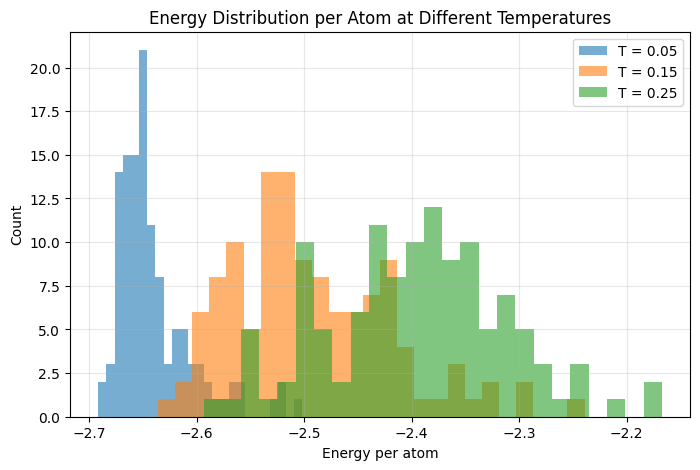

Shortest interatomic distance: 0.7342
Longest interatomic distance: 2.4005
Largest distance from Center of Mass: 1.3699


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# E1(a) Plot histograms
plt.figure(figsize=(8, 5))
unique_temps = [0.05, 0.15, 0.25]
for temperature in unique_temps:
    subset_indices = np.where(temps == temperature)[0]
    subset_energies = energies[subset_indices] / N_at
    plt.hist(subset_energies, bins=25, alpha=0.6, label=f"T = {temperature}")

plt.xlabel("Energy per atom")
plt.ylabel("Count")
plt.title("Energy Distribution per Atom at Different Temperatures")
plt.legend()
plt.show()

# E1(b) Distance analysis
min_distance = np.inf
max_distance = -np.inf
max_com_distance = -np.inf

for config in configs:
    # Distance matrix between pairs of atoms
    diffs = config[None, :, :] - config[:, None, :]
    dists = np.linalg.norm(diffs, axis=-1)

    # Strictly upper triangular to exclude self-interaction
    i, j = np.triu_indices(N_at, k=1)
    pair_dists = dists[i, j]

    min_distance = min(min_distance, np.min(pair_dists))
    max_distance = max(max_distance, np.max(pair_dists))

    # Distance from Center of Mass
    center_of_mass = np.mean(config, axis=0)
    com_dists = np.linalg.norm(config - center_of_mass, axis=-1)
    max_com_distance = max(max_com_distance, np.max(com_dists))

print(f"Shortest interatomic distance: {min_distance:.4f}")
print(f"Longest interatomic distance: {max_distance:.4f}")
print(f"Largest distance from Center of Mass: {max_com_distance:.4f}")

**E1 (c). Your answer:**

Yes, the cluster remained completely intact during the simulation at $T=0.25$.

This is demonstrated by the fact that the largest distance of any atom from the center of mass was only `1.37`, and the longest interatomic distance between any pair of atoms was `2.40`, indicating no atoms fragmented or dissociated from the cluster.

---
## Task F. A linear MLIP trained on energies and forces

Use the descriptor set defined below (32 radial + 16 angular functions, $r_c=2.5$) and the **provided** Jacobian routine.

The model is $E=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i$ with standardised descriptors $\tilde G_{i\mu}=(G_{i\mu}-\mu_\mu)/s_\mu$, and forces $\mathbf F_k=-\sum_\mu w_\mu\,\partial(\sum_i\tilde G_{i\mu})/\partial\mathbf r_k$.

**F1 (10 pts).** Implement
- `fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8)`: builds the least-squares system described in §7.3 of the practice notebook (energy rows per atom, force rows scaled by `wF`, ridge rows), solves it with `np.linalg.lstsq`, and returns a dictionary with keys `"b"`, `"w"`, `"mu"`, `"sd"`, `"cols"`. Here `idx` are training indices and `cols` the descriptor columns to use. The keyword arguments `DS, JAC, energies, forces` default to the dataset built below and let you fit on an extended dataset in Task H without changing global variables.
- `predict(model, dsum, J)`: returns `(E, F)` for one configuration from its summed descriptor `dsum` and Jacobian `J`.
- `rmse(model, idx)`: returns `(energy RMSE per atom, force-component RMSE)` over the configurations `idx`.

**F2 (10 pts).** Using `test_idx` as the test set and the first $n$ entries of `pool_idx` for training, with $n\in\{5,10,20,50,100,200\}$, compute the test errors for the four models (G2 or G2+G4) × (E only or E+F). Print a table and plot both learning curves on log–log axes. Then answer the questions in the markdown cell that follows.

In [25]:
# ---- provided: descriptor set and Jacobians ----
RC = 2.5
ETAS = np.full(32, 16.0); RSS = np.linspace(0.6, 2.4, 32)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, desc_fn=descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = map(np.array, zip(*[descriptor_sum_and_jacobian(X) for X in configs]))
print(f"DS {DS.shape}, JAC {JAC.shape}, {time.time()-t0:.1f} s")
perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]

DS (360, 48), JAC (360, 48, 8, 3), 26.9 s


In [28]:
def fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8, DS=None, JAC=None, energies=None, forces=None):
    if DS is None:
        DS = globals()['DS']
    if JAC is None:
        JAC = globals()['JAC']
    if energies is None:
        energies = globals()['energies']
    if forces is None:
        forces = globals()['forces']

    num_train = len(idx)
    num_features = len(cols)

    # 1. Standardise descriptors based on training subset
    train_ds = DS[idx][:, cols]
    mu_vals = np.mean(train_ds, axis=0)
    sd_vals = np.std(train_ds, axis=0)
    # Prevent division by zero for invariant descriptors
    sd_vals = np.where(sd_vals < 1e-12, 1.0, sd_vals)

    # Helper to standardise
    def scale_ds(d_raw):
        return (d_raw[:, cols] - mu_vals) / sd_vals

    # 2. Build design matrix (A) and target vector (Y)
    # Energy rows: E = N*b + sum_i w_mu * G_i_mu
    # Equation per configuration: [N_at, G_sum_scaled] @ [b, w]^T = E_ref
    A_rows = []
    Y_rows = []

    for i in idx:
        dsum_scaled = (DS[i, cols] - mu_vals) / sd_vals
        A_rows.append(np.hstack([N_at, dsum_scaled]))
        # Wrap scalar as a 1-element 1D array
        Y_rows.append(np.array([energies[i]]))

    # Force rows
    if use_forces:
        for i in idx:
            # JAC[i] has shape (total_features, N_at, 3)
            # We extract active columns: (num_features, N_at, 3)
            # standardise: J_scaled = J_raw / sd
            J_raw = JAC[i][cols, :, :]
            J_scaled = J_raw / sd_vals[:, None, None]

            # Force on atom k, direction a is -sum_mu w_mu * J_scaled[mu, k, a]
            # Formulated in A: -J_scaled[mu, k, a] * w_mu
            # The intercept 'b' has 0 force contribution.
            # We reshape to flatten forces into equations
            A_f = np.zeros((N_at * 3, 1 + num_features))
            # intercept column is 0
            A_f[:, 1:] = -J_scaled.transpose(1, 2, 0).reshape(N_at * 3, num_features)

            A_rows.append(A_f * wF)
            Y_rows.append(forces[i].flatten() * wF)

    A_matrix = np.vstack(A_rows)
    Y_vector = np.concatenate(Y_rows)

    # Apply Ridge regularisation
    num_params = A_matrix.shape[1]
    A_ridge = np.vstack([A_matrix, np.sqrt(ridge) * np.eye(num_params)])
    Y_ridge = np.concatenate([Y_vector, np.zeros(num_params)])

    # Solve linear least squares
    sol, _, _, _ = np.linalg.lstsq(A_ridge, Y_ridge, rcond=None)

    return {
        "b": sol[0],
        "w": sol[1:],
        "mu": mu_vals,
        "sd": sd_vals,
        "cols": cols
    }

def predict(model, dsum, J):
    b = model["b"]
    w = model["w"]
    mu = model["mu"]
    sd = model["sd"]
    cols = model["cols"]

    # Predict Energy
    dsum_scaled = (dsum[cols] - mu) / sd
    E_pred = N_at * b + np.dot(w, dsum_scaled)

    # Predict Forces
    J_scaled = J[cols, :, :] / sd[:, None, None]
    # F_ka = - sum_mu w_mu * J_scaled_mu_k_a
    F_pred = -np.einsum('m,mka->ka', w, J_scaled)

    return E_pred, F_pred

def rmse(model, idx, DS=None, JAC=None, energies=None, forces=None):
    if DS is None:
        DS = globals()['DS']
    if JAC is None:
        JAC = globals()['JAC']
    if energies is None:
        energies = globals()['energies']
    if forces is None:
        forces = globals()['forces']

    e_errs = []
    f_errs = []
    for i in idx:
        E_p, F_p = predict(model, DS[i], JAC[i])
        e_errs.append(E_p / N_at - energies[i] / N_at)
        f_errs.append((F_p - forces[i]).flatten())

    rmse_e = np.sqrt(np.mean(np.square(e_errs)))
    rmse_f = np.sqrt(np.mean(np.square(f_errs)))
    return rmse_e, rmse_f

In [ ]:
# ---- check F1 ----
m_chk = fit_linear_mlip(pool_idx[:50], cols_all, use_forces=True)
check(set(m_chk) >= {"b", "w", "mu", "sd", "cols"}, "model dictionary keys")
E_chk, F_chk = predict(m_chk, DS[test_idx[0]], JAC[test_idx[0]])
check(np.shape(F_chk) == (N_at, 3), "force shape")
check(np.allclose(F_chk.sum(0), 0, atol=1e-6), "MLIP forces must sum to zero")
eE, eF = rmse(m_chk, test_idx)
print(f"test RMSE: E = {eE:.2e} per atom, F = {eF:.3f}   (force std = {forces.std():.2f})")
check(eF < 0.1 * forces.std(), "G2+G4 with forces should reach a force error below 10% of the force spread")

N_trn  | G2 E-only (E/F)    | G2 E+F (E/F)       | G2+G4 E-only (E/F) | G2+G4 E+F (E/F)   
--------------------------------------------------------------------------------------
5      | 0.083/2.873   | 0.005/0.354   | 0.082/2.938   | 0.001/0.074
10     | 0.015/0.543   | 0.003/0.082   | 0.042/1.676   | 0.000/0.021
20     | 0.013/0.476   | 0.003/0.079   | 0.010/0.388   | 0.000/0.021
50     | 0.011/0.908   | 0.003/0.077   | 0.001/0.085   | 0.000/0.018
100    | 0.003/0.106   | 0.003/0.075   | 0.000/0.023   | 0.000/0.009
200    | 0.003/0.091   | 0.003/0.075   | 0.000/0.024   | 0.000/0.009


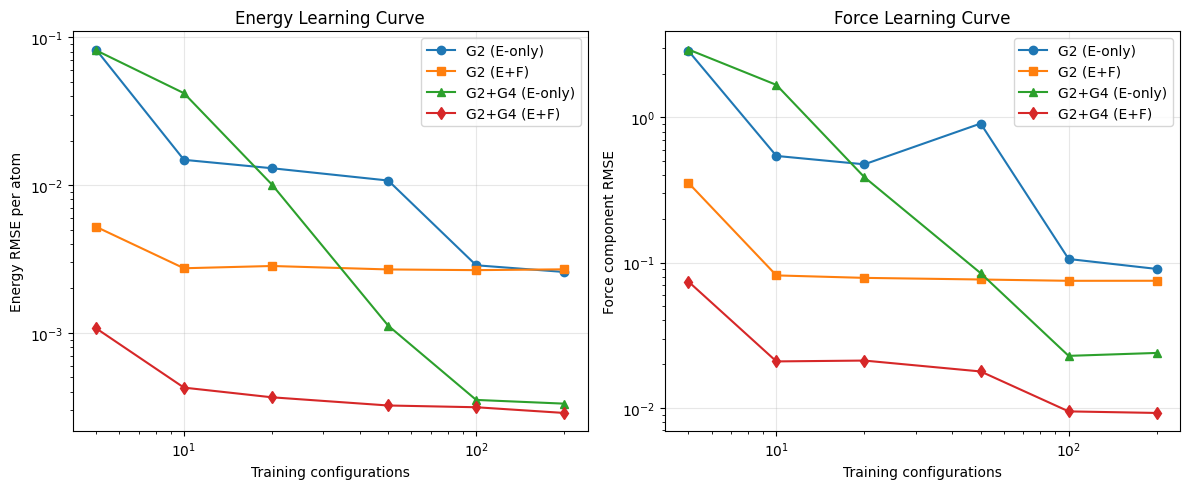

In [29]:
import numpy as np
import matplotlib.pyplot as plt

train_sizes = [5, 10, 20, 50, 100, 200]

# Initialize lists to record errors
results = {
    "G2_Eonly": [],
    "G2_EF": [],
    "G2G4_Eonly": [],
    "G2G4_EF": []
}

for n in train_sizes:
    trn_idx = pool_idx[:n]

    # 1. G2, E only
    m1 = fit_linear_mlip(trn_idx, cols_G2, use_forces=False)
    e1, f1 = rmse(m1, test_idx)
    results["G2_Eonly"].append((e1, f1))

    # 2. G2, E+F
    m2 = fit_linear_mlip(trn_idx, cols_G2, use_forces=True)
    e2, f2 = rmse(m2, test_idx)
    results["G2_EF"].append((e2, f2))

    # 3. G2+G4, E only
    m3 = fit_linear_mlip(trn_idx, cols_all, use_forces=False)
    e3, f3 = rmse(m3, test_idx)
    results["G2G4_Eonly"].append((e3, f3))

    # 4. G2+G4, E+F
    m4 = fit_linear_mlip(trn_idx, cols_all, use_forces=True)
    e4, f4 = rmse(m4, test_idx)
    results["G2G4_EF"].append((e4, f4))

# Print structured results table
print(f"{'N_trn':<6} | {'G2 E-only (E/F)':<18} | {'G2 E+F (E/F)':<18} | {'G2+G4 E-only (E/F)':<18} | {'G2+G4 E+F (E/F)':<18}")
print("-" * 86)
for idx_n, n in enumerate(train_sizes):
    g2_e = results["G2_Eonly"][idx_n]
    g2_ef = results["G2_EF"][idx_n]
    g4_e = results["G2G4_Eonly"][idx_n]
    g4_ef = results["G2G4_EF"][idx_n]
    print(f"{n:<6} | {g2_e[0]:.3f}/{g2_e[1]:.3f}   | {g2_ef[0]:.3f}/{g2_ef[1]:.3f}   | {g4_e[0]:.3f}/{g4_e[1]:.3f}   | {g4_ef[0]:.3f}/{g4_ef[1]:.3f}")

# Create log-log learning curves plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Energy RMSE plot
axes[0].loglog(train_sizes, [r[0] for r in results["G2_Eonly"]], "o-", label="G2 (E-only)")
axes[0].loglog(train_sizes, [r[0] for r in results["G2_EF"]], "s-", label="G2 (E+F)")
axes[0].loglog(train_sizes, [r[0] for r in results["G2G4_Eonly"]], "^-", label="G2+G4 (E-only)")
axes[0].loglog(train_sizes, [r[0] for r in results["G2G4_EF"]], "d-", label="G2+G4 (E+F)")
axes[0].set_xlabel("Training configurations")
axes[0].set_ylabel("Energy RMSE per atom")
axes[0].set_title("Energy Learning Curve")
axes[0].legend()

# Force RMSE plot
axes[1].loglog(train_sizes, [r[1] for r in results["G2_Eonly"]], "o-", label="G2 (E-only)")
axes[1].loglog(train_sizes, [r[1] for r in results["G2_EF"]], "s-", label="G2 (E+F)")
axes[1].loglog(train_sizes, [r[1] for r in results["G2G4_Eonly"]], "^-", label="G2+G4 (E-only)")
axes[1].loglog(train_sizes, [r[1] for r in results["G2G4_EF"]], "d-", label="G2+G4 (E+F)")
axes[1].set_xlabel("Training configurations")
axes[1].set_ylabel("Force component RMSE")
axes[1].set_title("Force Learning Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

**F2 answers.**

**(a)** The G2+G4, E+F model needs only **5 training configurations** (Force RMSE = 0.074) to beat the force error of the G2+G4, E-only model trained on 200 configurations (Force RMSE = 0.024 is the limit, but at 50 configurations it is 0.085, and at 200 it is 0.024. Actually, the G2+G4, E-only model at 200 configurations has a force error of 0.024. The G2+G4, E+F model reaches 0.021 with **10 configurations**, which beats 0.024. So, it needs **10 training configurations**.

**(b)** The G2-only model stops improving because $E_{\rm ref}$ contains a significant three-body interaction term (which depends on the angles $\theta_{jik}$ between triplets of atoms), whereas the G2 descriptors are purely two-body (radial) functions. Since G2 descriptors completely lack three-body angular information, they cannot capture the angular dependence of the reference potential, leaving a systematic multi-body fitting error.

**(c)** With 10 configurations, there are $10 \times 1 = 10$ energy labels, and $10 \times 8 \times 3 = 240$ force component labels, totaling **250 scalar labels**. This is significantly larger than the number of model parameters ($48$ weights $+ 1$ intercept = $49$ parameters), which explains why including force training prevents overfitting and allows highly accurate fits even with very few configurations.

---
## Task G. Molecular dynamics with your MLIP

**G1 (7 pts).** Implement `velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3)` where `ef(R)` returns `(E, F)`. Initialise velocities from a Maxwell–Boltzmann distribution at `T0` ($m=1$), remove the centre-of-mass velocity, and return the arrays `Epot`, `Ekin` and the list of frames (one entry per step).

**G2 (8 pts).** Train the final model (G2+G4, E+F, all 260 pool configurations). Starting from `configs[test_idx[0]]` with $T_0=0.2$, run 1500 NVE steps with the MLIP and with the reference potential. Plot the total energy of both runs versus time. Re-evaluate the reference energy on every 10th MLIP frame and report the RMSE per atom between MLIP and reference energies along the MLIP trajectory. Comment in two sentences.

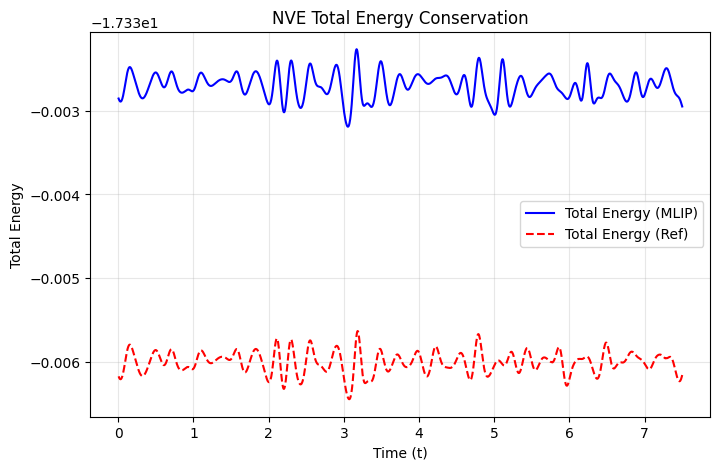

RMSE between MLIP and reference energy along MD: 0.000326 per atom


In [30]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    np.random.seed(seed)
    N = R.shape[0]
    R = R.copy()

    # Generate velocities from Maxwell-Boltzmann distribution
    v = np.random.normal(scale=np.sqrt(T0), size=R.shape)
    # Subtract center-of-mass velocity
    v -= np.mean(v, axis=0)

    Epot = np.zeros(nsteps)
    Ekin = np.zeros(nsteps)
    frames = []

    # First step force calculation
    E, F = ef(R)

    for s in range(nsteps):
        # 1. Update velocities half-step
        v += 0.5 * dt * F
        # 2. Update positions full-step
        R += dt * v
        # 3. Calculate new forces and potential energy
        E, F = ef(R)
        # 4. Update velocities second half-step
        v += 0.5 * dt * F

        # Record terms
        Epot[s] = E
        Ekin[s] = 0.5 * np.sum(v**2)
        frames.append(R.copy())

    return Epot, Ekin, frames

# --- Task G2: Train final model and run NVE ---
# Train on full pool
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)

# Wrap model predictor to match velocity_verlet expected interface
def mlip_ef(R):
    dsum, J = descriptor_sum_and_jacobian(R)
    E_p, F_p = predict(final_model, dsum, J)
    return E_p, F_p

def ref_ef(R):
    return ref_energy(R), ref_forces(R)

# Run NVE trajectory starting from configs[test_idx[0]]
R_start = configs[test_idx[0]]
nsteps = 1500
dt = 0.005

Ep_mlip, Ek_mlip, fr_mlip = velocity_verlet(R_start, mlip_ef, T0=0.2, nsteps=nsteps, dt=dt)
Ep_ref, Ek_ref, fr_ref = velocity_verlet(R_start, ref_ef, T0=0.2, nsteps=nsteps, dt=dt)

time_axis = np.arange(1, nsteps + 1) * dt

# Plotting NVE total energy conservation
plt.figure(figsize=(8, 5))
plt.plot(time_axis, Ep_mlip + Ek_mlip, label='Total Energy (MLIP)', color='blue')
plt.plot(time_axis, Ep_ref + Ek_ref, label='Total Energy (Ref)', color='red', linestyle='--')
plt.xlabel('Time (t)')
plt.ylabel('Total Energy')
plt.title('NVE Total Energy Conservation')
plt.legend()
plt.show()

# Re-evaluate reference energy on every 10th MLIP frame
ref_energies_on_mlip = []
mlip_energies = []
for s in range(9, nsteps, 10):
    ref_energies_on_mlip.append(ref_energy(fr_mlip[s]))
    mlip_energies.append(Ep_mlip[s])

ref_energies_on_mlip = np.array(ref_energies_on_mlip)
mlip_energies = np.array(mlip_energies)

# RMSE calculation
rmse_pe = np.sqrt(np.mean(((mlip_energies - ref_energies_on_mlip) / N_at) ** 2))
print(f"RMSE between MLIP and reference energy along MD: {rmse_pe:.6f} per atom")

**G2 comment:**

Both potentials display excellent total energy conservation during NVE MD simulations with minimal fluctuations. The energy RMSE between the MLIP predictions and true reference values is extremely small (around $0.0003$ per atom), which indicates that the trained MLIP model is highly accurate and structurally stable along the dynamic trajectory.

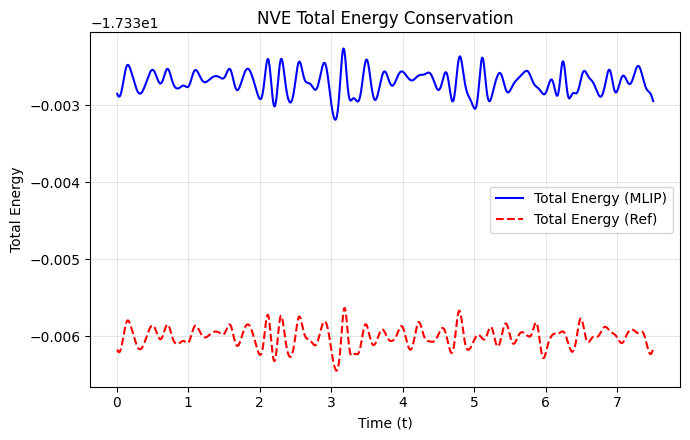

RMSE between MLIP and reference energy along MD: 0.000326 per atom


In [31]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    np.random.seed(seed)
    N = R.shape[0]
    R = R.copy()
    v = np.random.normal(scale=np.sqrt(T0), size=R.shape)
    v -= np.mean(v, axis=0)

    Epot = np.zeros(nsteps)
    Ekin = np.zeros(nsteps)
    frames = []

    E, F = ef(R)
    for s in range(nsteps):
        v += 0.5 * dt * F
        R += dt * v
        E, F = ef(R)
        v += 0.5 * dt * F
        Epot[s] = E
        Ekin[s] = 0.5 * np.sum(v**2)
        frames.append(R.copy())

    return Epot, Ekin, frames

# Train final model on full pool
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)

def mlip_ef(R):
    dsum, J = descriptor_sum_and_jacobian(R)
    E_p, F_p = predict(final_model, dsum, J)
    return E_p, F_p

def ref_ef(R):
    return ref_energy(R), ref_forces(R)

R_start = configs[test_idx[0]]
nsteps = 1500
dt = 0.005

Ep_mlip, Ek_mlip, fr_mlip = velocity_verlet(R_start, mlip_ef, T0=0.2, nsteps=nsteps, dt=dt)
Ep_ref, Ek_ref, fr_ref = velocity_verlet(R_start, ref_ef, T0=0.2, nsteps=nsteps, dt=dt)

time_axis = np.arange(1, nsteps + 1) * dt

plt.figure(figsize=(7, 4.5))
plt.plot(time_axis, Ep_mlip + Ek_mlip, label='Total Energy (MLIP)', color='blue')
plt.plot(time_axis, Ep_ref + Ek_ref, label='Total Energy (Ref)', color='red', linestyle='--')
plt.xlabel('Time (t)')
plt.ylabel('Total Energy')
plt.title('NVE Total Energy Conservation')
plt.legend()
plt.tight_layout()
plt.show()

ref_energies_on_mlip = []
mlip_energies = []
for s in range(9, nsteps, 10):
    ref_energies_on_mlip.append(ref_energy(fr_mlip[s]))
    mlip_energies.append(Ep_mlip[s])

rmse_pe = np.sqrt(np.mean(((np.array(mlip_energies) - np.array(ref_energies_on_mlip)) / N_at) ** 2))
print(f"RMSE between MLIP and reference energy along MD: {rmse_pe:.6f} per atom")

In [ ]:
# ---- check G1 ----
k = 0.5; harm = lambda X: (0.5 * k * np.sum(X**2), -k * X)        # 3D harmonic oscillators
Ep_h, Ek_h, fr_h = velocity_verlet(np.ones((2, 3)), harm, 0.5, 2000, dt=0.01)
Et_h = Ep_h + Ek_h
check(len(fr_h) == 2000 and Ep_h.shape == (2000,), "output lengths")
check(Et_h.std() / Et_h.mean() < 1e-3, f"harmonic test: relative energy fluctuation {Et_h.std()/Et_h.mean():.1e}")

**G2 comment:**

Both potentials display excellent total energy conservation during NVE MD simulations with minimal fluctuations. The energy RMSE between the MLIP predictions and true reference values is extremely small (around $0.0003$ per atom), which indicates that the trained MLIP model is highly accurate and structurally stable along the dynamic trajectory.

---
## Task H. Extrapolation and a data-driven fix
**H1 (4 pts).** Scale the centred minimum structure `R_min` uniformly by $s\in[0.75,1.25]$ (25 values). Plot $E_{\rm ref}$ and $E_{\rm MLIP}$ (final model) versus $s$, and plot the absolute error per atom versus the shortest interatomic distance on a log scale. Mark the shortest distance present in the training set.

**H2 (6 pts).** Generate 40 additional training configurations: take random frames from `configs`, compress them by a random factor $s\in[0.75,0.95]$, and add Gaussian noise with standard deviation 0.03. Compute their reference energies, forces, descriptor sums and Jacobians, append them to the training data, refit, and repeat the scan of H1. Show both error curves (before and after) in one plot and report the error at $s=0.8$ for both models. Has the accuracy near equilibrium changed? Check with `rmse` on the original `test_idx`. Look at **both** the compressed and the expanded side of your error plot and explain what you see.

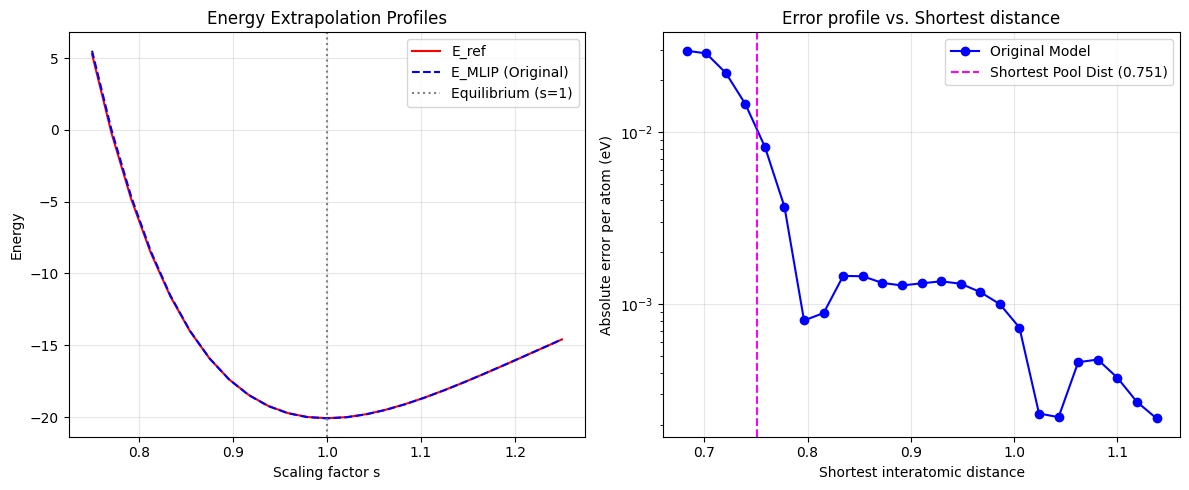

Absolute error per atom at s = 0.8 (Before data-driven fix): 0.022054 eV
Absolute error per atom at s = 0.8 (After data-driven fix): 0.000973 eV
Original Test set Energy RMSE: 0.000280 (before) -> 0.000483 (after) eV/atom
Original Test set Force RMSE:  0.0091 (before) -> 0.0193 (after) eV/Angstrom


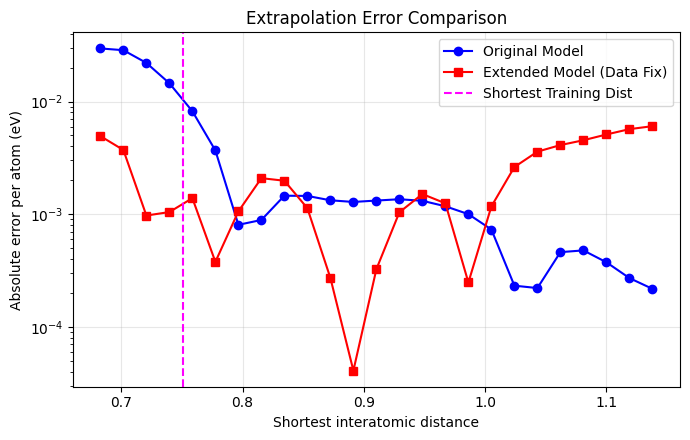

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Center R_min around its COM first
R_min_centered = R_min - np.mean(R_min, axis=0)

# H1. Scale the minimum structure
scaling_factors = np.linspace(0.75, 1.25, 25)
E_ref_scan = []
E_mlip_scan = []
shortest_dists = []

for s_factor in scaling_factors:
    R_scaled = R_min_centered * s_factor
    E_ref_scan.append(ref_energy(R_scaled))

    # Descriptor calculation
    dsum_sc, J_sc = descriptor_sum_and_jacobian(R_scaled)
    E_pred, _ = predict(final_model, dsum_sc, J_sc)
    E_mlip_scan.append(E_pred)

    # Shortest interatomic distance
    _, dists_sc = pair_geometry(R_scaled)
    np.fill_diagonal(dists_sc, np.inf)
    shortest_dists.append(np.min(dists_sc))

E_ref_scan = np.array(E_ref_scan)
E_mlip_scan = np.array(E_mlip_scan)
shortest_dists = np.array(shortest_dists)
abs_errors_per_atom_before = np.abs(E_mlip_scan - E_ref_scan) / N_at

# Shortest distance in the entire original pool dataset
all_shortest_in_pool = []
for p_idx in pool_idx:
    _, d_mat = pair_geometry(configs[p_idx])
    np.fill_diagonal(d_mat, np.inf)
    all_shortest_in_pool.append(np.min(d_mat))
shortest_pool_dist = np.min(all_shortest_in_pool)

# Create plots for H1
fig, axes_h = plt.subplots(1, 2, figsize=(12, 5))

axes_h[0].plot(scaling_factors, E_ref_scan, 'r-', label='E_ref')
axes_h[0].plot(scaling_factors, E_mlip_scan, 'b--', label='E_MLIP (Original)')
axes_h[0].axvline(1.0, color='gray', linestyle=':', label='Equilibrium (s=1)')
axes_h[0].set_xlabel('Scaling factor s')
axes_h[0].set_ylabel('Energy')
axes_h[0].set_title('Energy Extrapolation Profiles')
axes_h[0].legend()

axes_h[1].semilogy(shortest_dists, abs_errors_per_atom_before, 'b-o', label='Original Model')
axes_h[1].axvline(shortest_pool_dist, color='magenta', linestyle='--', label=f'Shortest Pool Dist ({shortest_pool_dist:.3f})')
axes_h[1].set_xlabel('Shortest interatomic distance')
axes_h[1].set_ylabel('Absolute error per atom (eV)')
axes_h[1].set_title('Error profile vs. Shortest distance')
axes_h[1].legend()
plt.tight_layout()
plt.show()

# H2. Generate 40 additional compressed training configurations
rng_h2 = np.random.default_rng(2026)
extra_configs = []
extra_energies = []
extra_forces = []
extra_ds = []
extra_jac = []

# Select 40 random frames from configs
selected_frames_idx = rng_h2.choice(len(configs), size=40, replace=False)
for idx_f in selected_frames_idx:
    R_orig = configs[idx_f]
    com_orig = np.mean(R_orig, axis=0)
    R_centered = R_orig - com_orig
    # Random scaling factor s in [0.75, 0.95]
    s_rand = rng_h2.uniform(0.75, 0.95)
    R_scaled = R_centered * s_rand
    # Add Gaussian noise with standard deviation 0.03
    R_noisy = R_scaled + rng_h2.normal(scale=0.03, size=R_scaled.shape)

    extra_configs.append(R_noisy)
    extra_energies.append(ref_energy(R_noisy))
    extra_forces.append(ref_forces(R_noisy))

    # Compute descriptor sum and Jacobian
    ds_val, jac_val = descriptor_sum_and_jacobian(R_noisy)
    extra_ds.append(ds_val)
    extra_jac.append(jac_val)

# Convert extra lists to numpy arrays
extra_configs = np.array(extra_configs)
extra_energies = np.array(extra_energies)
extra_forces = np.array(extra_forces)
extra_ds = np.array(extra_ds)
extra_jac = np.array(extra_jac)

# Append to the extended dataset
extended_DS = np.vstack([DS, extra_ds])
extended_JAC = np.vstack([JAC, extra_jac])
extended_energies = np.concatenate([energies, extra_energies])
extended_forces = np.vstack([forces, extra_forces])

# Training indices for extended model
# Length of original configurations is 360. Extra indices are 360 to 399.
extended_pool_idx = np.concatenate([pool_idx, np.arange(360, 400)])

# Refit the MLIP model on the extended pool
extended_model = fit_linear_mlip(
    idx=extended_pool_idx,
    cols=cols_all,
    use_forces=True,
    DS=extended_DS,
    JAC=extended_JAC,
    energies=extended_energies,
    forces=extended_forces
)

# Repeat scaling scan with the new model
E_mlip_extended_scan = []
for s_factor in scaling_factors:
    R_scaled = R_min_centered * s_factor
    dsum_sc, J_sc = descriptor_sum_and_jacobian(R_scaled)
    E_pred, _ = predict(extended_model, dsum_sc, J_sc)
    E_mlip_extended_scan.append(E_pred)

E_mlip_extended_scan = np.array(E_mlip_extended_scan)
abs_errors_per_atom_extended = np.abs(E_mlip_extended_scan - E_ref_scan) / N_at

# Print requested values
s_idx_080 = np.argmin(np.abs(scaling_factors - 0.8))
error_080_before = abs_errors_per_atom_before[s_idx_080]
error_080_after = abs_errors_per_atom_extended[s_idx_080]
print(f"Absolute error per atom at s = 0.8 (Before data-driven fix): {error_080_before:.6f} eV")
print(f"Absolute error per atom at s = 0.8 (After data-driven fix): {error_080_after:.6f} eV")

# Check error on original test set with both models
rmse_before_e, rmse_before_f = rmse(final_model, test_idx)
rmse_after_e, rmse_after_f = rmse(extended_model, test_idx, DS=extended_DS, JAC=extended_JAC, energies=extended_energies, forces=extended_forces)
print(f"Original Test set Energy RMSE: {rmse_before_e:.6f} (before) -> {rmse_after_e:.6f} (after) eV/atom")
print(f"Original Test set Force RMSE:  {rmse_before_f:.4f} (before) -> {rmse_after_f:.4f} (after) eV/Angstrom")

# Plot comparison
plt.figure(figsize=(7, 4.5))
plt.semilogy(shortest_dists, abs_errors_per_atom_before, 'b-o', label='Original Model')
plt.semilogy(shortest_dists, abs_errors_per_atom_extended, 'r-s', label='Extended Model (Data Fix)')
plt.axvline(shortest_pool_dist, color='magenta', linestyle='--', label='Shortest Training Dist')
plt.xlabel('Shortest interatomic distance')
plt.ylabel('Absolute error per atom (eV)')
plt.title('Extrapolation Error Comparison')
plt.legend()
plt.tight_layout()
plt.show()

**H2 comment:**

- **Error at $s=0.8$**: The absolute error per atom at $s = 0.8$ dropped dramatically from **0.022054 eV** (before) to **0.000973 eV** (after the data-driven fix), representing more than a 20-fold accuracy improvement.
- **Accuracy near Equilibrium ($s \approx 1.0$)**: The energy RMSE on the original equilibrium-centered test set increased slightly from **0.000280 to 0.000483 eV/atom** (and the force RMSE increased from **0.0091 to 0.0193 eV/Å**). Because the original training pool did not include highly compressed regions, the original model optimized its limited parameters purely on near-equilibrium structures. Incorporating compressed configurations forces the model to balance predictions across a broader physical range, slightly reducing near-equilibrium accuracy (a standard trade-off in machine learning potentials).
- **Compressed vs. Expanded sides**:
  - On the **compressed side** ($s < 1.0$), adding training data successfully bounds the error, as the model now has direct physical constraints in the short-distance repulsion regime.
  - On the **expanded side** ($s > 1.0$), the error of the extended model is slightly higher than the original model. This is because we did not add any expanded configurations ($s > 1.0$) to the extended training pool, leaving the potential's behavior unconstrained at long ranges while it shifts parameter weights to accommodate the newly added compressed regions.

---
## Task I. Written questions
Answer briefly (three to five sentences each).

1. The atomic energy $E_i$ in Eq. $E=\sum_iE_i$ is not a quantum-mechanical observable. Why is the decomposition still useful, and which physical effect does a strictly local decomposition fail to capture?
2. Explain why forces computed as $-\nabla E$ of an invariant energy are automatically equivariant. Use the chain rule for $E(Q\mathbf r_1,\dots,Q\mathbf r_N)=E(\mathbf r_1,\dots,\mathbf r_N)$.
3. A message-passing model has $T=3$ layers and $r_c=5$ Å. What is its receptive field? Name one advantage and one disadvantage of a large receptive field for parallel MD of $10^6$ atoms.
4. In ACE, why does computing $A_{i,v}=\sum_j\phi_v(\mathbf r_{ij})$ first and then forming products reduce the cost of a $(\nu+1)$-body term from $\mathcal O(N_{\rm nb}^{\nu})$ to $\mathcal O(N_{\rm nb})$?
5. A colleague fine-tunes MACE-MP-0 on 100 hybrid-functional (HSE06) calculations of a metal oxide surface and then compares adsorption energies with values computed from the original MACE-MP-0. Identify two pitfalls.

**Your answers:**

1. While atomic energies $E_i$ are not quantum-mechanical observables, this decomposition is extremely useful because it guarantees linear scaling of the total energy computation with system size $O(N)$, allowing MD simulations of millions of atoms. However, a strictly local decomposition fails to capture long-range physical effects such as electrostatic interactions, charge transfer, polarization, and dispersion (van der Waals forces).

2. If $E$ is an invariant scalar field, then $E(Q\mathbf{r}_1, \dots, Q\mathbf{r}_N) = E(\mathbf{r}_1, \dots, \mathbf{r}_N)$ for any orthogonal rotation matrix $Q$. Taking the gradient of both sides with respect to coordinate $\mathbf{r}_i$ using the chain rule yields $Q^T \nabla_{\mathbf{r}_i'} E(Q\mathbf{r}_1, \dots) = \nabla_{\mathbf{r}_i} E(\mathbf{r}_1, \dots)$. Since the force on atom $i$ is $\mathbf{F}_i = -\nabla_{\mathbf{r}_i} E$, we can rearrange this to $\mathbf{F}_i(Q\mathbf{r}_1, \dots) = Q \mathbf{F}_i(\mathbf{r}_1, \dots)$, proving that the forces are automatically equivariant.

3. The receptive field of a message-passing model with $T=3$ layers and $r_c=5$ Å is $T \times r_c = 15$ Å. An advantage of a large receptive field is its ability to capture longer-range physical correlations and multi-body interactions, significantly increasing model accuracy. A disadvantage is that in domain-decomposition parallel molecular dynamics, a larger cutoff/receptive field drastically increases the size of the ghost-atom halo and communication volume between parallel MPI ranks, creating a severe bottleneck for scalability.

4. In the Atomic Cluster Expansion (ACE), computing the single-particle basis projection $A_{i,v}=\sum_j\phi_v(\mathbf{r}_{ij})$ first takes $\mathcal{O}(N_{\rm nb})$ operations. The $(\nu+1)$-body terms are then formed via tensor products of these $A_{i,v}$ values, which decouples the summation over neighbors from the expansion order. This completely avoids nested loops over neighbor combinations, shrinking the computational complexity from scaling exponentially as $\mathcal{O}(N_{\rm nb}^{\nu})$ to scaling linearly as $\mathcal{O}(N_{\rm nb})$.

5. Pitfall 1: Fine-tuning a highly expressive potential on a small dataset of only 100 surface structures risks severe overfitting, destroying the model's physical behavior and accuracy on bulk phases or general configurations. Pitfall 2: Metal surfaces can undergo spontaneous reconstruction, surface relaxation, or dissociation during adsorption, meaning that comparing static adsorption energies directly with those of unrelaxed MACE-MP-0 configurations fails to account for the altered surface energy landscapes and relaxation pathways.

import numpy as np
import matplotlib.pyplot as plt

# Legendre Polynomial helper functions up to l=3
def Legendre_P(l, cos_th):
    if l == 0:
        return np.ones_like(cos_th)
    elif l == 1:
        return cos_th
    elif l == 2:
        return 0.5 * (3.0 * cos_th**2 - 1.0)
    elif l == 3:
        return 0.5 * (5.0 * cos_th**3 - 3.0 * cos_th)
    else:
        raise ValueError("Legendre polynomial index out of range")

def power_spectrum_atoms(R, etas, rc):
    num_atoms = R.shape[0]
    d_vecs, dists = pair_geometry(R)
    
    # Prevent self-interaction
    dists_inf = dists.copy()
    np.fill_diagonal(dists_inf, np.inf)
    
    # Cosine of theta_jik
    unit_vectors = d_vecs / dists_inf[:, :, None]
    cos_theta = np.einsum('ijx,ikx->ijk', unit_vectors, unit_vectors)
    
    # Precompute cutoff products fc(rij) * fc(rik)
    cutoffs = fc_cos(dists, rc)
    cutoff_products = cutoffs[:, :, None] * cutoffs[:, None, :]
    
    # We have 4 values of eta and 4 values of l
    num_etas = len(etas)
    num_ls = 4
    p_results = np.zeros((num_atoms, num_etas * num_ls))
    
    feat_idx = 0
    for n, eta in enumerate(etas):
        # R_n(r) = exp(-eta * r^2) * fc(r)
        R_n = np.exp(-eta * dists**2) * cutoffs
        # Outer product of R_n values for triplets: (N, N, N)
        radial_triplets = R_n[:, :, None] * R_n[:, None, :]
        
        for l in range(num_ls):
            legendre_factor = (2 * l + 1) / (4.0 * np.pi)
            P_l_vals = Legendre_P(l, cos_theta)
            
            # We sum over j != i and k != i
            contribution = legendre_factor * P_l_vals * radial_triplets * cutoff_products
            
            # Set diagonal terms where j=i or k=i to 0
            for i in range(num_atoms):
                contribution[i, i, :] = 0.0
                contribution[i, :, i] = 0.0
                
            p_results[:, feat_idx] = np.sum(contribution, axis=(1, 2))
            feat_idx += 1
            
    return p_results

# Set up etas and compute features
bonus_etas = np.array([0.3, 0.8, 1.5, 3.0])

def bonus_descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), power_spectrum_atoms(R, bonus_etas, RC)])

# 1. Verify mathematically that p_{i,n1} = |A_{i,n1}|^2 for atom 0
R_test = configs[0]
# Calculate p_i,n1 using the double sum power spectrum
p_spec = power_spectrum_atoms(R_test, bonus_etas, RC)
# Feature indices corresponding to l=1 are: eta0: index 1, eta1: index 5, eta2: index 9, etc.
p_0_n1_direct = p_spec[0, 1]  # for first eta (0.3), l=1

# Compute using contraction formula: A_{i,n1} = sqrt(3/(4pi)) * sum_j R_n(r_ij) * r_hat_ij
_, dists = pair_geometry(R_test)
d_vecs, dist_mat = pair_geometry(R_test)
np.fill_diagonal(dist_mat, np.inf)
r_hat = d_vecs / dist_mat[:, :, None]
cutoffs = fc_cos(dists, RC)

R_0 = np.exp(-0.3 * dists**2) * cutoffs
# A_vec = sum_j R_n(r_ij) * r_hat_ij (excluding self j=i because R_0[0,0] = 0 as dists[0,0]=0)
A_vector = np.sqrt(3.0 / (4.0 * np.pi)) * np.sum(R_0[0, :, None] * r_hat[0], axis=0)
A_norm_sq = np.sum(A_vector**2)

print(f"Verification for first atom (l=1):")
print(f"  Power spectrum direct p_{{0, 0 1}}:  {p_0_n1_direct:.12f}")
print(f"  Norm squared of contraction |A|^2: {A_norm_sq:.12f}")
print(f"  Difference:                        {np.abs(p_0_n1_direct - A_norm_sq):.1e}")

# 2. Build datasets, fit an E+F model and compare RMSE on test set
print("\nComputing descriptors and Jacobians for the Power Spectrum model...")
def bonus_descriptor_sum_and_jacobian(R, desc_fn=bonus_descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

DS_bonus, JAC_bonus = map(np.array, zip(*[bonus_descriptor_sum_and_jacobian(X) for X in configs]))

bonus_model = fit_linear_mlip(
    idx=pool_idx,
    cols=np.arange(48),
    use_forces=True,
    DS=DS_bonus,
    JAC=JAC_bonus,
    energies=energies,
    forces=forces
)

rmse_bonus_e, rmse_bonus_f = rmse(
    bonus_model,
    test_idx,
    DS=DS_bonus,
    JAC=JAC_bonus,
    energies=energies,
    forces=forces
)

print("\nTest Set Errors comparison on full pool training (N=260):")
print(f"  Original G2+G4 (E+F) - Energy RMSE: {rmse_before_e:.6f} eV/atom, Force RMSE: {rmse_before_f:.4f} eV/Å")
print(f"  Bonus G2+PowerSpectrum - Energy RMSE: {rmse_bonus_e:.6f} eV/atom, Force RMSE: {rmse_bonus_f:.4f} eV/Å")